In [0]:

from pyspark.sql import functions as F

# Load the cleaned Delta Lake table
df = spark.table(
    "workspace.default.dmart_sales_clean"
)

print("Task 2: DMart MapReduce Analysis")
print("Total Records:", df.count())
print("Total Columns:", len(df.columns))

display(
    df.select(
        "ProductCategory",
        "Quantity",
        "Total"
    ).limit(10)
)


Task 2: DMart MapReduce Analysis
Total Records: 1000000
Total Columns: 14


ProductCategory,Quantity,Total
Grocery,4,42.76
Home & Kitchen,3,1143.09
Grocery,5,769.2
Electronics,4,1365.64
Home & Kitchen,5,1950.8
Grocery,4,680.84
Clothing,2,163.48
Clothing,3,543.78
Electronics,2,943.78
Grocery,2,119.4


In [0]:

# MAP STAGE
# Select the information needed for analysis

df_mapped = df.select(
    "ProductCategory",
    "Quantity",
    "Total"
)

print("Map Stage Completed")
print("Mapped Records:", df_mapped.count())

display(df_mapped.limit(10))


Map Stage Completed
Mapped Records: 1000000


ProductCategory,Quantity,Total
Grocery,4,42.76
Home & Kitchen,3,1143.09
Grocery,5,769.2
Electronics,4,1365.64
Home & Kitchen,5,1950.8
Grocery,4,680.84
Clothing,2,163.48
Clothing,3,543.78
Electronics,2,943.78
Grocery,2,119.4


In [0]:

# REDUCE STAGE
# Aggregate sales information by product category

df_reduced = (
    df_mapped
    .groupBy("ProductCategory")
    .agg(
        F.round(F.sum("Total"), 2).alias("TotalSales"),
        F.sum("Quantity").alias("TotalQuantity"),
        F.count("*").alias("Transactions")
    )
    .orderBy(F.desc("TotalSales"))
)

print("MapReduce Analysis Completed")

display(df_reduced)


MapReduce Analysis Completed


ProductCategory,TotalSales,TotalQuantity,Transactions
Beauty & Personal Care,1.5337800339E8,601258,199892
Home & Kitchen,1.5331603272E8,601642,200424
Clothing,1.5318490842E8,599606,199927
Electronics,1.5271964445E8,599271,200113
Grocery,1.5249603041E8,597547,199644


In [0]:

# Prepare category revenue for visualisation
df_sales_chart = df_reduced.select(
    "ProductCategory",
    "TotalSales"
).orderBy(F.desc("TotalSales"))

display(df_sales_chart)


ProductCategory,TotalSales
Beauty & Personal Care,1.5337800339E8
Home & Kitchen,1.5331603272E8
Clothing,1.5318490842E8
Electronics,1.5271964445E8
Grocery,1.5249603041E8


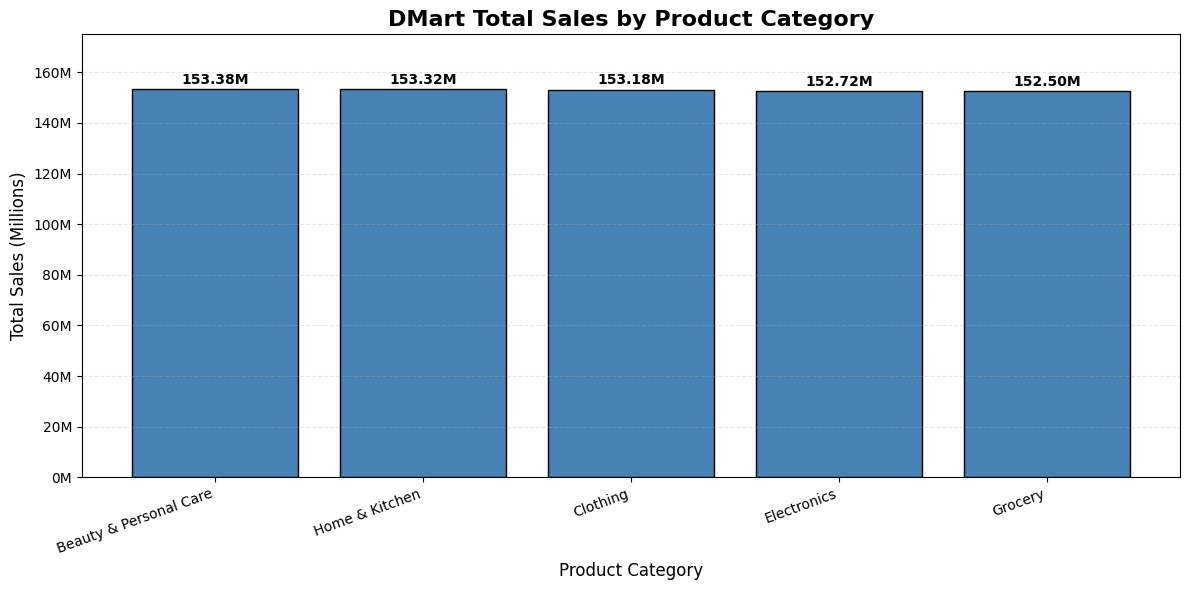

In [0]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Convert aggregated Spark results to Pandas
sales_pd = df_reduced.select(
    "ProductCategory",
    "TotalSales"
).orderBy(F.desc("TotalSales")).toPandas()

# Create bar chart
plt.figure(figsize=(12, 6))

bars = plt.bar(
    sales_pd["ProductCategory"],
    sales_pd["TotalSales"],
    color="steelblue",
    edgecolor="black"
)

# Add values above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 2000000,
        f"{height/1000000:.2f}M",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# Format Y-axis in millions
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x/1e6:.0f}M")
)

plt.title(
    "DMart Total Sales by Product Category",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Sales (Millions)", fontsize=12)

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 175000000)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [0]:

# Examine the Spark MapReduce execution plan

print("DMart MapReduce Physical Execution Plan")

df_reduced.explain(mode="formatted")


DMart MapReduce Physical Execution Plan
== Physical Plan ==
AdaptiveSparkPlan (6)
+- == Initial Plan ==
   PhotonResultStage (5)
   +- PhotonColumnarToRow (4)
      +- PhotonSort (3)
         +- PhotonGroupingAgg (2)
            +- PhotonScan parquet workspace.default.dmart_sales_clean (1)


(1) PhotonScan parquet workspace.default.dmart_sales_clean
Output [3]: [ProductCategory#13458, Quantity#13460, Total#13461]
Location: PreparedDeltaFileIndex [s3://dbstorage-prod-zm7qas0dn2/uc/8bca585b-2624-4449-a326-c04ddcc0ba68/5f200a07-a276-43f4-bd45-b92f90078c9f/__unitystorage/catalogs/b9b1a287-547a-4f3e-9943-9156cbb0f8d7/tables/90dded40-0386-4542-8ea6-c5d8d166d7c7]
ReadSchema: struct<ProductCategory:string,Quantity:int,Total:double>

(2) PhotonGroupingAgg
Input [3]: [ProductCategory#13458, Quantity#13460, Total#13461]
Arguments: [ProductCategory#13458], [sum(Total#13461), sum(Quantity#13460), count(1)], [sum(Total)#13472, sum(Quantity)#13473L, count(1)#13469L], [ProductCategory#13458, round(sum

In [0]:

from pyspark.sql import functions as F

# Distribute mapped records into four partitions
df_map_partitioned = df_mapped.repartition(4)

# Count records in each partition
df_partition_counts = (
    df_map_partitioned
    .withColumn(
        "PartitionID",
        F.spark_partition_id()
    )
    .groupBy("PartitionID")
    .agg(
        F.count("*").alias("RecordCount")
    )
    .orderBy("PartitionID")
)

print("MapReduce Input Partition Distribution")

display(df_partition_counts)


MapReduce Input Partition Distribution


PartitionID,RecordCount
0,250000
1,250000
2,250000
3,250000


In [0]:

# REDUCE after repartitioning

df_partition_reduced = (
    df_map_partitioned
    .groupBy("ProductCategory")
    .agg(
        F.round(F.sum("Total"), 2).alias("TotalSales"),
        F.sum("Quantity").alias("TotalQuantity"),
        F.count("*").alias("Transactions")
    )
    .orderBy(F.desc("TotalSales"))
)

print("Reduce Stage After Partitioning")

display(df_partition_reduced)


Reduce Stage After Partitioning


ProductCategory,TotalSales,TotalQuantity,Transactions
Beauty & Personal Care,1.5337800339E8,601258,199892
Home & Kitchen,1.5331603272E8,601642,200424
Clothing,1.5318490842E8,599606,199927
Electronics,1.5271964445E8,599271,200113
Grocery,1.5249603041E8,597547,199644


In [0]:

# Compare original and repartitioned results

comparison = (
    df_reduced.alias("a")
    .join(
        df_partition_reduced.alias("b"),
        on="ProductCategory",
        how="full"
    )
    .select(
        "ProductCategory",
        F.col("a.TotalSales").alias("OriginalSales"),
        F.col("b.TotalSales").alias("PartitionedSales"),
        F.round(
            F.abs(
                F.col("a.TotalSales") -
                F.col("b.TotalSales")
            ), 2
        ).alias("SalesDifference"),
        (
            F.col("a.TotalQuantity") ==
            F.col("b.TotalQuantity")
        ).alias("QuantityMatches"),
        (
            F.col("a.Transactions") ==
            F.col("b.Transactions")
        ).alias("TransactionsMatch")
    )
)

display(comparison)


ProductCategory,OriginalSales,PartitionedSales,SalesDifference,QuantityMatches,TransactionsMatch
Home & Kitchen,1.5331603272E8,1.5331603272E8,0.0,true,true
Grocery,1.5249603041E8,1.5249603041E8,0.0,true,true
Electronics,1.5271964445E8,1.5271964445E8,0.0,true,true
Clothing,1.5318490842E8,1.5318490842E8,0.0,true,true
Beauty & Personal Care,1.5337800339E8,1.5337800339E8,0.0,true,true


In [0]:

# Compare original and repartitioned results

comparison = (
    df_reduced.alias("a")
    .join(
        df_partition_reduced.alias("b"),
        on="ProductCategory",
        how="full"
    )
    .select(
        "ProductCategory",
        F.col("a.TotalSales").alias("OriginalSales"),
        F.col("b.TotalSales").alias("PartitionedSales"),
        F.round(
            F.abs(
                F.col("a.TotalSales") -
                F.col("b.TotalSales")
            ), 2
        ).alias("SalesDifference"),
        (
            F.col("a.TotalQuantity") ==
            F.col("b.TotalQuantity")
        ).alias("QuantityMatches"),
        (
            F.col("a.Transactions") ==
            F.col("b.Transactions")
        ).alias("TransactionsMatch")
    )
)

display(comparison)


ProductCategory,OriginalSales,PartitionedSales,SalesDifference,QuantityMatches,TransactionsMatch
Home & Kitchen,1.5331603272E8,1.5331603272E8,0.0,true,true
Grocery,1.5249603041E8,1.5249603041E8,0.0,true,true
Electronics,1.5271964445E8,1.5271964445E8,0.0,true,true
Clothing,1.5318490842E8,1.5318490842E8,0.0,true,true
Beauty & Personal Care,1.5337800339E8,1.5337800339E8,0.0,true,true


In [0]:

import time
from pyspark.sql import functions as F

# Test different Spark partition counts
partition_options = [2, 4, 8, 16]
performance_results = []

for n in partition_options:

    start_time = time.perf_counter()

    # Repartition the mapped dataset
    df_test = df_mapped.repartition(n)

    # Run category sales aggregation
    result = (
        df_test
        .groupBy("ProductCategory")
        .agg(
            F.sum("Total").alias("TotalSales"),
            F.sum("Quantity").alias("TotalQuantity"),
            F.count("*").alias("Transactions")
        )
    )

    # Trigger execution and retrieve all 5 results
    output = result.collect()

    elapsed = time.perf_counter() - start_time

    performance_results.append((n, round(elapsed, 3)))

    print(
        f"Partitions: {n}, "
        f"Time: {elapsed:.3f} seconds, "
        f"Categories: {len(output)}"
    )

# Display benchmark results
performance_df = spark.createDataFrame(
    performance_results,
    ["Partitions", "ExecutionTimeSeconds"]
)

display(performance_df)


Partitions: 2, Time: 0.945 seconds, Categories: 5
Partitions: 4, Time: 0.893 seconds, Categories: 5
Partitions: 8, Time: 0.932 seconds, Categories: 5
Partitions: 16, Time: 0.891 seconds, Categories: 5


Partitions,ExecutionTimeSeconds
2,0.945
4,0.893
8,0.932
16,0.891


In [0]:

import time
import statistics
from pyspark.sql import functions as F

partition_options = [2, 4, 8, 16]
benchmark_results = []

# Run each partition configuration 3 times
for n in partition_options:

    times = []

    for run in range(3):

        start = time.perf_counter()

        df_test = df_mapped.repartition(n)

        result = (
            df_test
            .groupBy("ProductCategory")
            .agg(
                F.sum("Total").alias("TotalSales"),
                F.sum("Quantity").alias("TotalQuantity"),
                F.count("*").alias("Transactions")
            )
        )

        output = result.collect()

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    median_time = statistics.median(times)
    average_time = statistics.mean(times)

    benchmark_results.append(
        (
            n,
            round(average_time, 3),
            round(median_time, 3)
        )
    )

    print(
        f"Partitions: {n}, "
        f"Average: {average_time:.3f}s, "
        f"Median: {median_time:.3f}s"
    )

# Create final benchmark table
benchmark_summary = spark.createDataFrame(
    benchmark_results,
    ["Partitions", "AverageSeconds", "MedianSeconds"]
)

display(benchmark_summary)


Partitions: 2, Average: 0.907s, Median: 0.898s
Partitions: 4, Average: 0.893s, Median: 0.877s
Partitions: 8, Average: 0.928s, Median: 0.908s
Partitions: 16, Average: 1.005s, Median: 1.006s


Partitions,AverageSeconds,MedianSeconds
2,0.907,0.898
4,0.893,0.877
8,0.928,0.908
16,1.005,1.006


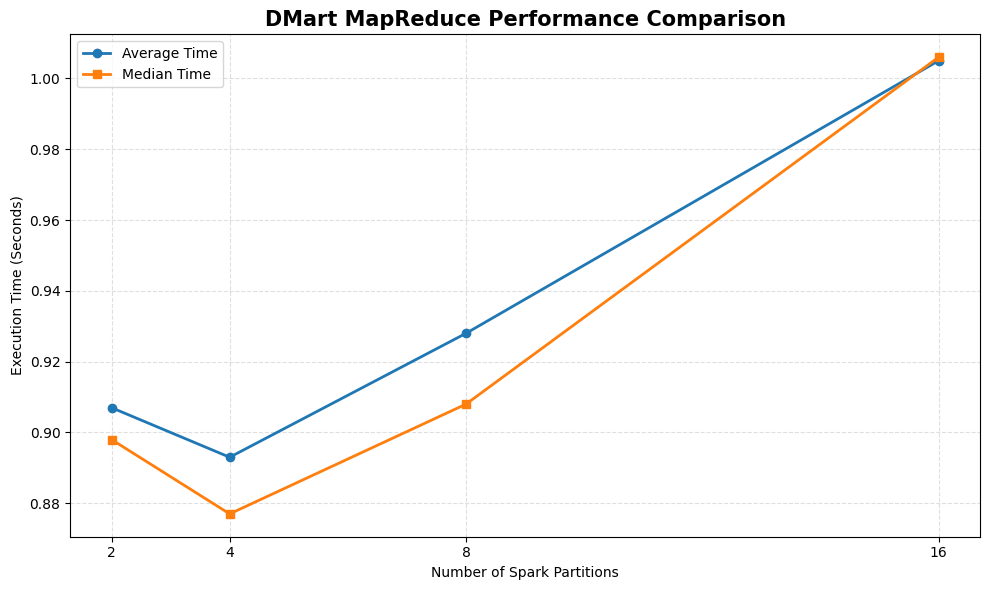

In [0]:

import matplotlib.pyplot as plt

# Convert small benchmark summary to Pandas
benchmark_pd = (
    benchmark_summary
    .orderBy("Partitions")
    .toPandas()
)

plt.figure(figsize=(10, 6))

plt.plot(
    benchmark_pd["Partitions"],
    benchmark_pd["AverageSeconds"],
    marker="o",
    linewidth=2,
    label="Average Time"
)

plt.plot(
    benchmark_pd["Partitions"],
    benchmark_pd["MedianSeconds"],
    marker="s",
    linewidth=2,
    label="Median Time"
)

plt.title(
    "DMart MapReduce Performance Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Spark Partitions")
plt.ylabel("Execution Time (Seconds)")

plt.xticks([2, 4, 8, 16])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()


In [0]:

# DMart MapReduce Compute Configuration

print("Project: DMart Big Data Analytics")
print("Compute Environment: Databricks Serverless")
print("Spark Version:", spark.version)

print(
    "Shuffle Partitions:",
    spark.conf.get("spark.sql.shuffle.partitions")
)

print("Execution Engine: Photon (verified from execution plan)")
print("Storage Format: Delta Lake")
print("Delta Table: workspace.default.dmart_sales_clean")

print(
    "Adaptive Query Execution: "
    "Configuration not exposed in Serverless"
)


Project: DMart Big Data Analytics
Compute Environment: Databricks Serverless
Spark Version: 4.2.0
Shuffle Partitions: auto
Execution Engine: Photon (verified from execution plan)
Storage Format: Delta Lake
Delta Table: workspace.default.dmart_sales_clean
Adaptive Query Execution: Configuration not exposed in Serverless
